In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
import seaborn as sns
from copy import deepcopy

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from modules.autolog import ASLT
from sklearn.preprocessing import StandardScaler,OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.cluster import DBSCAN
import optuna
from sklearn.base import clone

In [33]:
df = pd.read_csv('./abalone/abalone.data',header=None,names=['sex','length','diameter','height','whole_weight','shucked_weight','viscera_weight','shell_weight','rings'])
df['sex'] = df.pop('sex')
print(df.shape)
df.head()

(4177, 9)


,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,sex
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,M
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,M
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,F
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,M
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,I


In [34]:
print('NaN values of each columns:')
print(df.isna().sum())

NaN values of each columns:
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
sex               0
dtype: int64


In [35]:
print('Count of duplicated rows:')
print(df.duplicated().sum())

Count of duplicated rows:
0


In [36]:
print('Datatypes of each columns:')
print(df.dtypes)

Datatypes of each columns:
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
rings               int64
sex                object
dtype: object


# **Preprocessing**

In [37]:
from sklearn.model_selection import train_test_split

df_train,df_test = train_test_split(df,test_size=0.2,random_state=42)
print(df_train.shape,df_test.shape)

(3341, 9) (836, 9)


### **Removing Outliers with DBSCAN**

In [38]:
pl_out = Pipeline([
    ('scaler',StandardScaler()),
    ('cluster',DBSCAN(eps=1.5,min_samples=10))
])
outlier_indexs = pl_out.fit_predict(df_train.drop('sex',axis=1))
outlier_indexs = np.where(outlier_indexs == -1, 1, 0).astype(bool)
df_train_out = df_train[~outlier_indexs]
print(f'Removed {outlier_indexs.sum()} rows detected as outliers.')

df_train_out = df_train_out.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Removed 15 rows detected as outliers.


### **Preprocessing Pipeline**

In [39]:
num_cols = df.drop('sex',axis=1).select_dtypes(include='number').columns
cat_cols = df.drop('sex',axis=1).select_dtypes(exclude='number').columns
num_pl = Pipeline([
            ('aslt',ASLT(beta=10)),
            ('scaler',StandardScaler()),
            ('pca',PCA())
        ])
ct = ColumnTransformer([
    ('numeric',num_pl,num_cols),
    ('categorical',OrdinalEncoder(),cat_cols)
],remainder='passthrough')
ct

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

# **Modelling**

In [40]:
X_train = df_train_out.drop('sex',axis=1)
y_train = df_train_out['sex']

X_test = df_test.drop('sex',axis=1)
y_test = df_test['sex']

In [41]:
def objective(trial):
    pl = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',SVC(gamma='scale',degree=4))
    ])
    params = {
        'preprocess__numeric__aslt__beta': trial.suggest_float('preprocess__numeric__aslt__beta',-50,50),
        'preprocess__numeric__pca__n_components': trial.suggest_int('preprocess__numeric__pca__n_components',2,num_cols.shape[0]),
        'estimator__C': trial.suggest_float('estimator__C',1e-2,1e1),
        'estimator__kernel': trial.suggest_categorical('estimator__kernel',['linear','poly','rbf'])
    }
    pl.set_params(**params)
    score = cross_val_score(pl,X_train,y_train,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

study_svc = optuna.create_study(direction='maximize')
study_svc.optimize(objective,n_trials=50)

[I 2026-11-17 22:07:24,044] A new study created in memory with name: no-name-392d706f-d6f1-48b2-9dc1-5bae2e6dea9c
[I 2026-11-17 22:07:27,315] Trial 0 finished with value: 0.4600103848468018 and parameters: {'preprocess__numeric__aslt__beta': -31.43142297503314, 'preprocess__numeric__pca__n_components': 5, 'estimator__C': 8.710234086652058, 'estimator__kernel': 'poly'}. Best is trial 0 with value: 0.4600103848468018.
[I 2026-11-17 22:07:27,637] Trial 1 finished with value: 0.5321684370082385 and parameters: {'preprocess__numeric__aslt__beta': -32.570304503669234, 'preprocess__numeric__pca__n_components': 8, 'estimator__C': 7.799981526492661, 'estimator__kernel': 'linear'}. Best is trial 1 with value: 0.5321684370082385.
[I 2026-11-17 22:07:27,848] Trial 2 finished with value: 0.5456998345367028 and parameters: {'preprocess__numeric__aslt__beta': -12.774420175489745, 'preprocess__numeric__pca__n_components': 5, 'estimator__C': 0.8037877781152228, 'estimator__kernel': 'rbf'}. Best is tria

In [42]:
def objective(trial):
    pl = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',RandomForestClassifier())
    ])
    params = {
        'preprocess__numeric__aslt__beta': trial.suggest_float('preprocess__numeric__aslt__beta',-50,50),
        'preprocess__numeric__pca__n_components': trial.suggest_int('preprocess__numeric__pca__n_components',2,num_cols.shape[0]),
        'estimator__n_estimators': trial.suggest_int('estimator__n_estimators',10,500),
        'estimator__criterion': trial.suggest_categorical('estimator__criterion',['entropy','gini','log_loss'])
    }
    pl.set_params(**params)
    score = cross_val_score(pl,X_train,y_train,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective,n_trials=50)

[I 2026-11-17 22:07:40,172] A new study created in memory with name: no-name-3e59aa84-2b8b-4175-ac30-35b5be4f539f
[I 2026-11-17 22:07:40,989] Trial 0 finished with value: 0.5426932188975284 and parameters: {'preprocess__numeric__aslt__beta': 22.271008351424953, 'preprocess__numeric__pca__n_components': 6, 'estimator__n_estimators': 143, 'estimator__criterion': 'entropy'}. Best is trial 0 with value: 0.5426932188975284.
[I 2026-11-17 22:07:41,391] Trial 1 finished with value: 0.5120300784504305 and parameters: {'preprocess__numeric__aslt__beta': -17.17331120342405, 'preprocess__numeric__pca__n_components': 3, 'estimator__n_estimators': 110, 'estimator__criterion': 'log_loss'}. Best is trial 0 with value: 0.5426932188975284.
[I 2026-11-17 22:07:42,960] Trial 2 finished with value: 0.5312669947005462 and parameters: {'preprocess__numeric__aslt__beta': -16.9888867519657, 'preprocess__numeric__pca__n_components': 4, 'estimator__n_estimators': 389, 'estimator__criterion': 'gini'}. Best is tr

In [43]:
pl_svc = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',SVC(gamma='scale',degree=4))
    ])
pl_svc.set_params(**study_svc.best_params)
pl_svc.fit(X_train,y_train)
y_svc = pl_svc.predict(X_test)

pl_rf = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',RandomForestClassifier())
    ])
pl_rf.set_params(**study_rf.best_params)
pl_rf.fit(X_train,y_train)
y_rf = pl_rf.predict(X_test)

SVC =======================================================================


,F,I,M,accuracy,macro avg,weighted avg
precision,0.515337,0.745763,0.497354,0.588517,0.586152,0.582326
recall,0.320611,0.823970,0.612378,0.588517,0.585653,0.588517
f1-score,0.395294,0.782918,0.548905,0.588517,0.575706,0.575502
support,262.000000,267.000000,307.000000,0.588517,836.000000,836.000000


RF ========================================================================


,F,I,M,accuracy,macro avg,weighted avg
precision,0.436364,0.747368,0.468278,0.555024,0.550670,0.547411
recall,0.366412,0.797753,0.504886,0.555024,0.556350,0.555024
f1-score,0.398340,0.771739,0.485893,0.555024,0.551991,0.549747
support,262.000000,267.000000,307.000000,0.555024,836.000000,836.000000


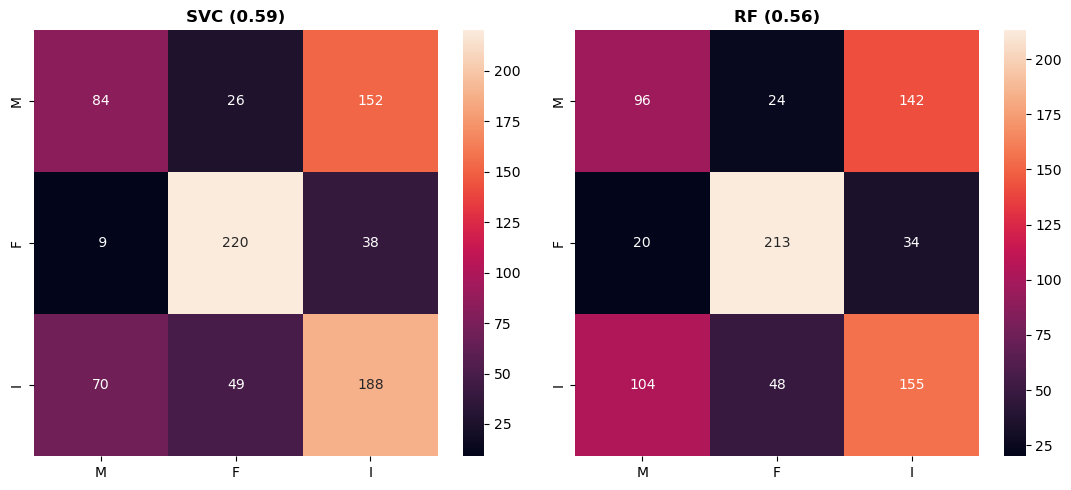

In [44]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,classification_report

svc_rpt = pd.DataFrame(classification_report(y_test,y_svc,output_dict=True)).rename(columns={'0.0':'Male','1.0':'Female','2.0':'Infant'})
rf_rpt = pd.DataFrame(classification_report(y_test,y_rf,output_dict=True)).rename(columns={'0.0':'Male','1.0':'Female','2.0':'Infant'})
print('SVC =======================================================================')
display(svc_rpt)

print('RF ========================================================================')
display(rf_rpt)

plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test,y_svc),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title(f'SVC ({accuracy_score(y_test,y_svc):.2f})',weight='bold')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test,y_rf),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title(f'RF ({accuracy_score(y_test,y_rf):.2f})',weight='bold')

plt.tight_layout()
plt.show()

# **Visualization**

In [45]:
handles = [
    patches.Patch(color=sns.color_palette('deep')[0],label='M'),
    patches.Patch(color=sns.color_palette('deep')[1],label='F'),
    patches.Patch(color=sns.color_palette('deep')[2],label='I')
]

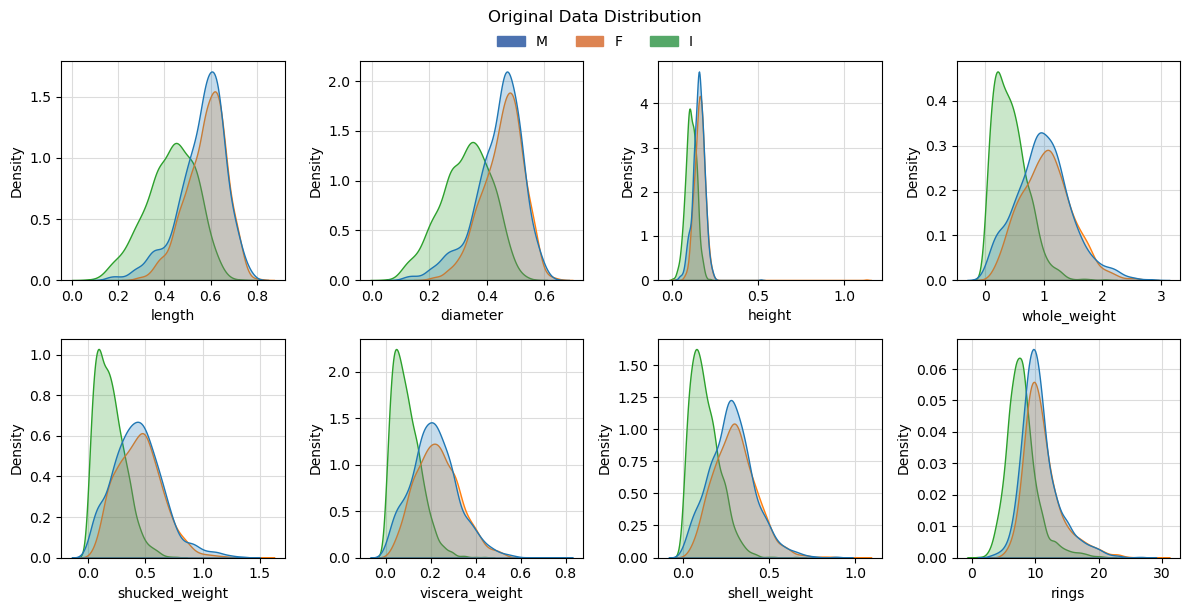

In [46]:
fig = plt.figure(figsize=(12,6))
for i,col in enumerate(df.columns):
    if col == 'sex':
        continue
    plt.subplot(2,4,i+1)
    plt.grid(color='gainsboro',zorder=1)
    sns.kdeplot(df,x=col,hue='sex',fill=True,zorder=2,hue_order=['M','F','I'],legend=False)
fig.legend(loc='upper center',frameon=False,ncols=3,handles=handles,bbox_to_anchor=(0.5,0.99))
plt.suptitle(f'Original Data Distribution',y=1.01)
plt.tight_layout()
plt.show()

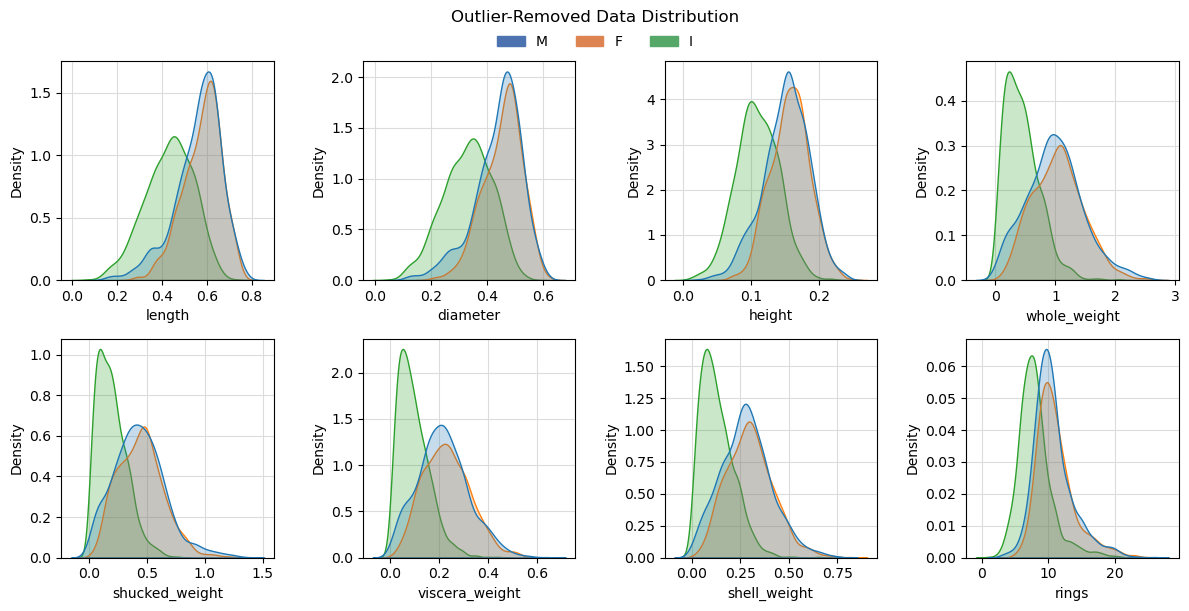

In [47]:
fig = plt.figure(figsize=(12,6))
for i,col in enumerate(df_train_out.columns):
    if col == 'sex':
        continue
    plt.subplot(2,4,i+1)
    plt.grid(color='gainsboro',zorder=1)
    sns.kdeplot(df_train_out,x=col,hue='sex',fill=True,zorder=2,hue_order=['M','F','I'],legend=False)
fig.legend(loc='upper center',frameon=False,ncols=3,handles=handles,bbox_to_anchor=(0.5,0.99))
plt.suptitle(f'Outlier-Removed Data Distribution',y=1.01)
plt.tight_layout()
plt.show()

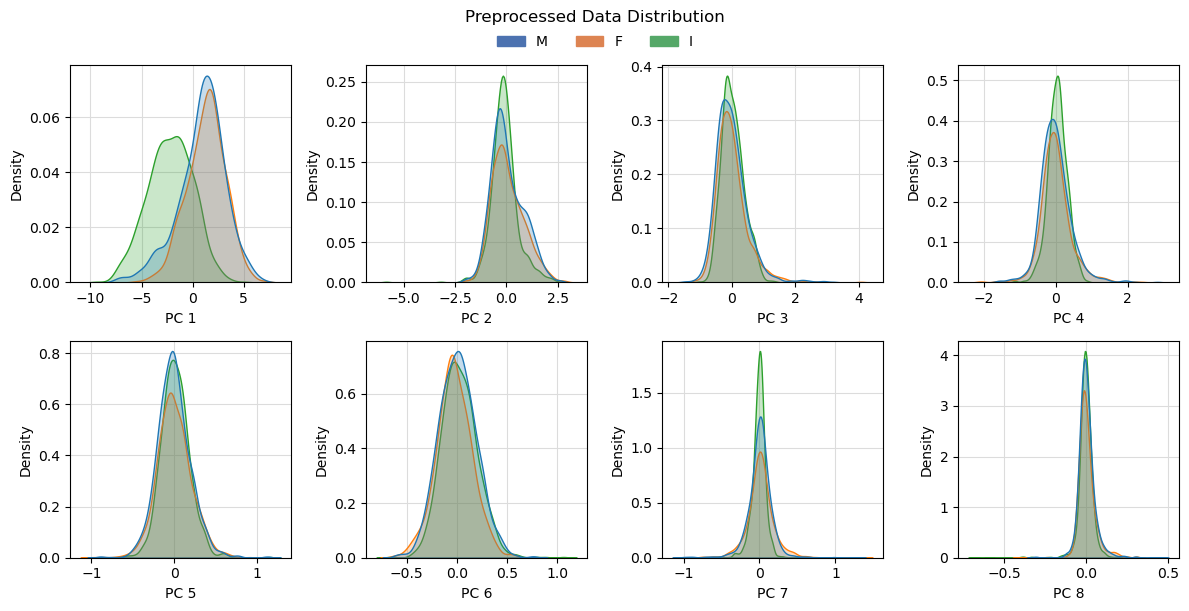

In [48]:
_vis_df = X_train.copy()
_ct = deepcopy(pl_svc).named_steps['preprocess']

_vis_df = _ct.transform(_vis_df)
_vis_df = pd.DataFrame(_vis_df,columns=[f'PC {i+1}' for i in range(_vis_df.shape[1])])
_vis_df['sex'] = y_train

fig = plt.figure(figsize=(12,6))
for i,col in enumerate(_vis_df):
    if col == 'sex':
        continue
    plt.subplot(2,4,i+1)
    plt.grid(color='gainsboro',zorder=1)
    sns.kdeplot(_vis_df,x=col,hue='sex',fill=True,zorder=2,hue_order=['M','F','I'],legend=False)
fig.legend(loc='upper center',frameon=False,ncols=3,handles=handles,bbox_to_anchor=(0.5,0.99))
plt.suptitle(f'Preprocessed Data Distribution',y=1.01)
plt.tight_layout()
plt.show()